# Qdislib — 04 · The circuit cache

Cutting is not free: one cut circuit becomes **many** subcircuits, and a lot of
them are *the same piece of physics wearing different clothes*. The same fragment
reappears across cut configurations, across observables, and across every
iteration of a variational loop.

The **semantic cache** notices this. It simulates each genuinely distinct
fragment **once** and serves every equivalent one from a store.

"Semantic" is the important word: the key is not a hash of the gate list. Each
circuit is reduced to a canonical **ZX-diagram** (PyZX `full_reduce`), turned
into a graph, and hashed with a Weisfeiler–Lehman graph hash. Two circuits that
implement the *same unitary* land on the same key even if they were written
completely differently.

This notebook uses the **LMDB** store — a persistent, on-disk cache. It needs no
server, it is shared by every process that can see the directory, and it
**survives the notebook**: stop the kernel, come back tomorrow, the work is
still there.

Look for the **🔧 Your turn** cells: change a line, re-run, watch it change.

![how a subcircuit becomes a cache key: the circuit is reduced to a ZX-calculus graph, fully reduced, abstracted to a NetworkX graph and hashed with Weisfeiler-Leman; the hash keys a persistent LMDB or Redis store, so a hit returns the stored result and a miss executes on CPU, GPU or QPU and stores it](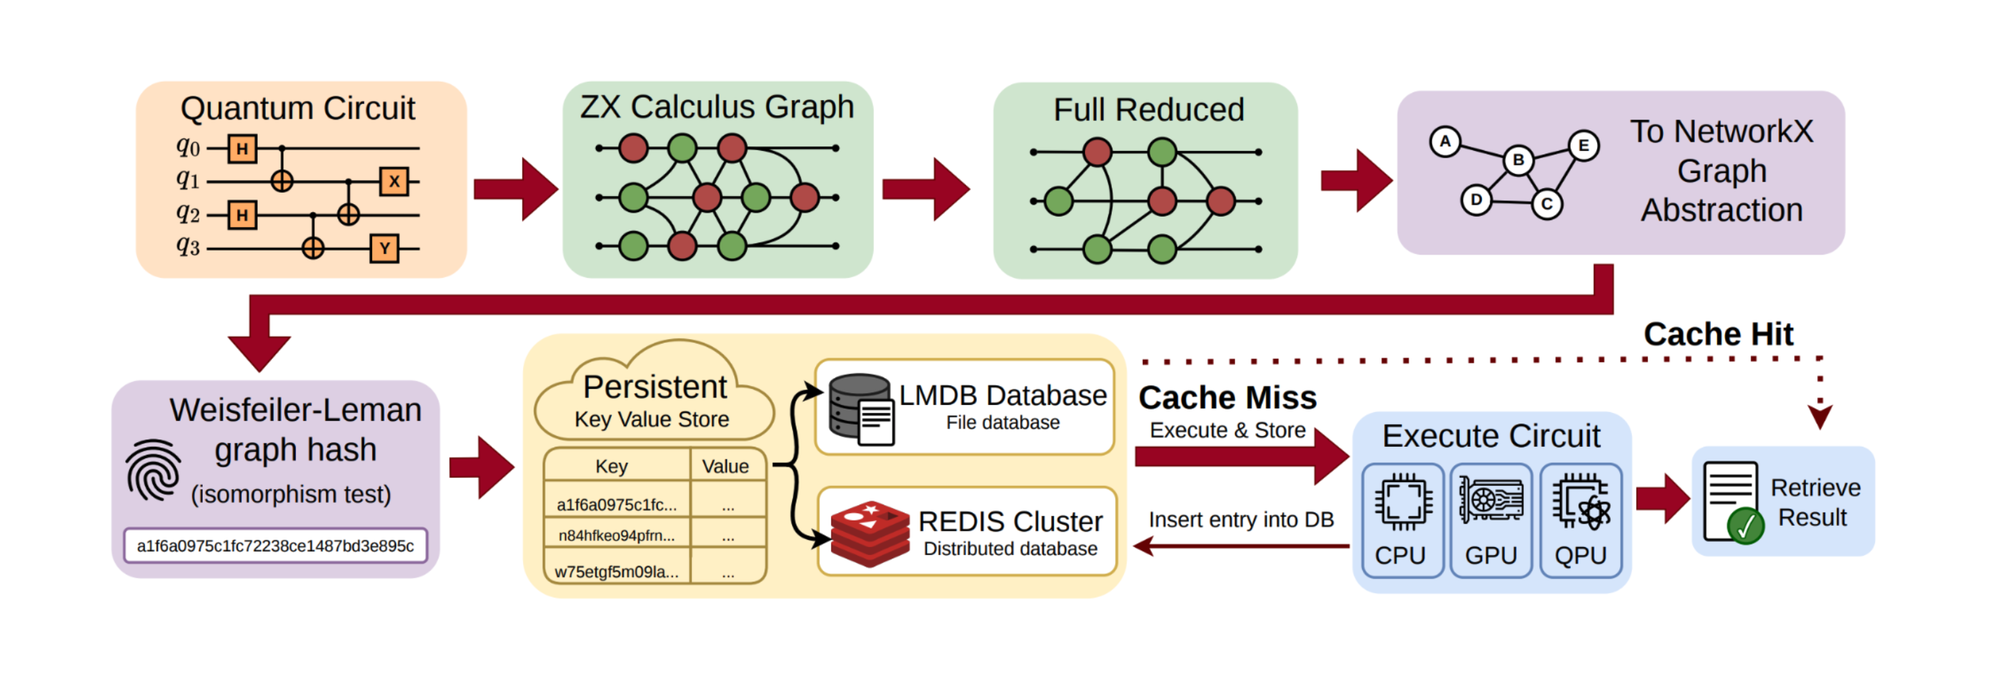)

## Start the PyCOMPSs runtime

This starts the COMPSs runtime **for the whole notebook**: the subcircuit
evaluations below run as parallel COMPSs `@task`s. Run the notebook top to
bottom; the last cells stop the runtime and draw the task graph.

In [ ]:
import pycompss.interactive as ipycompss
ipycompss.start(graph=True, monitor=1000)

In [ ]:
import os
import shutil
import time

from qibo import models, gates
import Qdislib as qd


def example_circuit():
    """The same 5-qubit circuit as notebook 01: cuttable, <ZZZZZ> ~= 0.44."""
    circuit = models.Circuit(5)
    circuit.add(gates.RY(0, 0.8))
    circuit.add(gates.CZ(0, 1))
    circuit.add(gates.RY(1, 0.5))
    circuit.add(gates.CZ(1, 2))
    circuit.add(gates.RY(2, 0.6))
    circuit.add(gates.CZ(2, 3))
    circuit.add(gates.RY(3, 0.4))
    circuit.add(gates.CZ(3, 4))
    circuit.add(gates.RX(4, 0.3))
    return circuit


cut = qd.find_cut(example_circuit(), gate_cut=False, wire_cut=True, seed=0)
print("cut:", cut)

## 1. Where the repetition comes from

Cutting one circuit produces a whole batch of subcircuits. Some of them are the
same piece of physics written twice. We'll count the pieces now and, in a
moment, let the cache tell us how many were genuinely distinct.

In [ ]:
subcircuits = qd.wire_cutting_subcircuits(
    example_circuit(), cut, observables="ZZZZZ", software="qibo"
)
n_subcircuits = len(subcircuits)
print("subcircuits generated:", n_subcircuits)

## 2. Switch the cache on

One line builds the store, one argument passes it to the cutting call.

`default_circuit_cache("lmdb", path=...)` needs a directory — anything on a
filesystem the workers can also see (on MareNostrum your home or the notebook
directory both work).

We wipe it first so this is an honest cold start. **Comment that line out** if
you want to keep results between runs — which is the whole point of LMDB.

In [ ]:
CACHE_DIR = os.path.join(os.getcwd(), "qdislib_cache")

shutil.rmtree(CACHE_DIR, ignore_errors=True)   # <-- comment out to keep the cache

cache = qd.default_circuit_cache("lmdb", path=CACHE_DIR)
print("store:", type(cache).__name__, "at", CACHE_DIR)

t0 = time.time()
value = qd.wire_cutting(example_circuit(), cut, observables="ZZZZZ",
                        shots=8192, software="qibo", cache=cache)
cold = time.time() - t0

print(f"value: {value:.6f}   time: {cold:.2f}s")
print(f"subcircuits generated: {n_subcircuits}")
print(f"entries in the cache : {len(cache)}")
print(f"→ {n_subcircuits - len(cache)} of them were duplicates of another fragment")

Compare the two counts. More subcircuits went in than entries came out — the
difference is fragments the cache recognised as *equivalent to one it had
already seen*, **within this single run**. Nothing was in the store when we
started, so that saving came entirely from the cut's own internal repetition.

> **Reading the numbers under PyCOMPSs.** Use `len(cache)` (the store's `size`),
> not the `hits`/`misses` in `stats()`. Those counters live on the store
> *instance*, and each PyCOMPSs worker gets its own pickled copy — so the ones
> you print here, on the master, will read `0` even while the cache is doing its
> job. `size` is read from the shared LMDB store, so it is global and true.

Now run exactly the same thing again. Every fragment is already known.

In [ ]:
# Repeat runs are fast, so time three of them and keep the best: under a shared
# scheduler a single sample can be hit by an unrelated stall.
warm_times = []
for _ in range(3):
    t0 = time.time()
    value_again = qd.wire_cutting(example_circuit(), cut, observables="ZZZZZ",
                                  shots=8192, software="qibo", cache=cache)
    warm_times.append(time.time() - t0)

warm = min(warm_times)
print("repeat runs:", "  ".join(f"{t:.2f}s" for t in warm_times))
print(f"value: {value_again:.6f}   best: {warm:.2f}s")
print(f"cache still holds {len(cache)} entries (nothing new to store)")
print()
print(f"cold: {cold:.2f}s   warm: {warm:.2f}s   speedup: {cold / warm:.1f}x")
print("same answer:", value == value_again)

**Caching never changes the answer.** It replaces a simulation with a lookup of
that simulation's result. If a circuit can't be keyed — PyZX missing, an
unsupported gate — Qdislib just simulates it as usual and carries on.

## 3. Semantic, not textual

Here is the part a plain hash of the gate list cannot do. `H·H·H` is the same
unitary as a single `H`. ZX-reduction collapses both to the same diagram, so
they share a key and the second one is free.

In [ ]:
from qibo import Circuit

one = Circuit(2)
one.add(gates.H(0))
one.add(gates.CZ(0, 1))
one.add(gates.M(0, 1))

three = Circuit(2)
for _ in range(3):
    three.add(gates.H(0))          # H*H*H == H
three.add(gates.CZ(0, 1))
three.add(gates.M(0, 1))

key_one, key_three = qd.semantic_key(one), qd.semantic_key(three)

print("different gate lists:", len(one.queue), "gates vs", len(three.queue))
if key_one is None or key_three is None:
    # Both None would compare equal and look like a match, so say what happened.
    print("semantic key        : unavailable -- install Qdislib[cache] (pyzx)")
else:
    print("key(H)              :", key_one)
    print("key(H*H*H)          :", key_three)
    print("same semantic key   :", key_one == key_three)

## 4. It survives the process

This is what LMDB buys over the in-memory store. We throw the `cache` object
away and build a **brand new one** pointing at the same directory — as a fresh
process, or tomorrow's kernel, would.

In [ ]:
reopened = qd.default_circuit_cache("lmdb", path=CACHE_DIR)
print("entries found on disk:", len(reopened))

t0 = time.time()
value_reopened = qd.wire_cutting(example_circuit(), cut, observables="ZZZZZ",
                                 shots=8192, software="qibo", cache=reopened)
print(f"value: {value_reopened:.6f}   time: {time.time() - t0:.2f}s")
print("still", len(reopened), "entries — served from disk, nothing re-simulated")

### 🔧 Your turn (1)

The default `cache_mode="expectation"` keys each entry by **fragment *and*
observable** — so a new observable is a genuine miss even though the same
fragments are involved. Watch the entry count *grow* the first time and stay
put the second.

Change `"ZIZIZ"` to another Pauli string (`"ZZIII"`, `"XZZZX"`, ...) and re-run.

In [ ]:
probe = qd.default_circuit_cache("lmdb", path=CACHE_DIR)
print("entries before:", len(probe))

for label in ["first time ", "second time"]:
    t0 = time.time()
    v = qd.wire_cutting(example_circuit(), cut, observables="ZIZIZ",   # <-- change me
                        shots=8192, software="qibo", cache=probe)
    print(f"{label}  value: {v:+.6f}   {time.time() - t0:.2f}s   entries: {len(probe)}")

## 5. One simulation, many observables

In section 4 each new observable added a fresh set of entries: the default
`cache_mode="expectation"` keys on **fragment *and* observable**.

If you plan to measure **several observables on the same fragments** — a
Hamiltonian is exactly this — `cache_mode="counts"` stores the raw measurement
counts keyed by the fragment **alone**, and applies the observable afterwards.
One simulation then serves them all.

Let's run the same three observables through both modes and watch the store
sizes diverge.

In [ ]:
OBSERVABLES = ["ZZZZZ", "ZIZIZ", "ZZIIZ"]

exp_cache = qd.default_circuit_cache("lmdb", path=os.path.join(CACHE_DIR, "mode_expectation"))
cnt_cache = qd.default_circuit_cache("lmdb", path=os.path.join(CACHE_DIR, "mode_counts"))

exp_entries, cnt_entries = [], []
for obs in OBSERVABLES:
    qd.wire_cutting(example_circuit(), cut, observables=obs, shots=8192,
                    software="qibo", cache=exp_cache)                      # default mode
    qd.wire_cutting(example_circuit(), cut, observables=obs, shots=8192,
                    software="qibo", cache=cnt_cache, cache_mode="counts")
    exp_entries.append(len(exp_cache))
    cnt_entries.append(len(cnt_cache))
    print(f"{obs}   expectation-mode: {exp_entries[-1]:3d} entries"
          f"   counts-mode: {cnt_entries[-1]:3d} entries")

## 6. The whole story in three plots

Everything above was printed numbers. Here they are as a picture — all drawn
from **this run's** measurements, so they will differ a little each time.

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
BLUE, GREY, WARM = "#2f6f9f", "#b9c4d0", "#d1604a"

# 1 - cold vs warm wall clock
ax1.bar(["first run", "repeat run"], [cold, warm], color=[GREY, BLUE], width=0.55)
for i, v in enumerate([cold, warm]):
    ax1.text(i, v, f" {v:.2f}s", ha="center", va="bottom", fontsize=10)
ratio = cold / warm
ax1.set_title("Wall clock" + (f"  ({ratio:.1f}x faster)" if ratio > 1 else ""),
              fontsize=11)
ax1.set_ylabel("seconds")
ax1.set_ylim(0, cold * 1.25)

# 2 - how much of the cutting was duplicated work
ax2.bar(["subcircuits\ngenerated", "actually\nsimulated"],
        [n_subcircuits, len(cache)], color=[GREY, BLUE], width=0.55)
for i, v in enumerate([n_subcircuits, len(cache)]):
    ax2.text(i, v, f" {v}", ha="center", va="bottom", fontsize=10)
ax2.set_title(f"Duplicate fragments: {n_subcircuits - len(cache)}", fontsize=11)
ax2.set_ylabel("count")
ax2.set_ylim(0, n_subcircuits * 1.25)

# 3 - the two cache modes as observables pile up
x = range(1, len(OBSERVABLES) + 1)
ax3.plot(x, exp_entries, "o-", color=WARM, lw=2, label='cache_mode="expectation"')
ax3.plot(x, cnt_entries, "s-", color=BLUE, lw=2, label='cache_mode="counts"')
ax3.set_title("Store size vs observables measured", fontsize=11)
ax3.set_xlabel("observables measured")
ax3.set_ylabel("entries in store")
ax3.set_xticks(list(x))
ax3.set_ylim(0, max(exp_entries) * 1.25)
ax3.legend(fontsize=9, loc="upper left")

for ax in (ax1, ax2, ax3):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.show()

## 7. The same cache, in front of a QPU

Everything so far saved *simulator* time. Put a real device behind the cache and
the same de-duplication saves something much scarcer: calls to a shared quantum
computer, each one queued behind everyone else's.

These are the sixteen **wire-cut** fragments of notebook 01's circuit — wire
cutting because every fragment must be QPU-runnable (no mid-circuit
measurement). The values were measured on **MareNostrum Ona**.

In [ ]:
import json
import pathlib
import sys

# The Ona data lives in a hidden folder, so the file browser shows only notebooks.
QCE26_DATA = next(
    (p for p in (pathlib.Path(".qce26"), pathlib.Path(".")) if (p / "ona_results.json").exists()),
    pathlib.Path(".qce26"),
)
if str(QCE26_DATA) not in sys.path:
    sys.path.insert(0, str(QCE26_DATA))

record = json.loads((QCE26_DATA / "ona_results.json").read_text())
print("source:", record["source"], "\n")

total = len(record["fragments"])
distinct = record["distinct_circuits"]
measured = {f["index"]: f["value"] for f in record["fragments"]}

print(f"fragments to evaluate : {total}")
print(f"distinct circuits     : {distinct}")
print(f"QPU calls avoided     : {total - distinct}"
      f"  ({100 * (1 - distinct / total):.0f}% of the device time)")

print("\nEach duplicate was sent to Ona twice, so we can compare what the cache")
print("would have returned against what the hardware actually said:\n")
print(f"  {'fragments':<12} {'1st':>9} {'2nd':>9} {'|diff|':>8}")
for indices in record["duplicate_groups"]:
    first = indices[0]
    for other in indices[1:]:
        print(f"  {str(first) + ' and ' + str(other):<12} {measured[first]:>+9.4f} "
              f"{measured[other]:>+9.4f} {abs(measured[first] - measured[other]):>8.4f}")
print(f"\nshot noise at {record['shots']} shots is about {1 / record['shots'] ** 0.5:.4f}")
print(f"grouping: {record['grouping']}")


Six of the sixteen fragments are circuits the device has already run. The cache
returns those without a second submission — **38% less time on the QPU**, for a
result that is identical by construction.

The right-hand column is the honest check. Each pair really was executed twice
on Ona, and the two runs agree at the shot-noise scale (one pair drifts to
~3 sigma — real hardware also drifts between submissions). So the value the
cache hands back is as good as the one a re-run would have produced, and it
costs nothing.

This is the argument for caching in one line: **on a simulator the cache saves
seconds; in front of a QPU it saves queue.** And it compounds with everything
else here — the semantic key of section 3 means fragments that merely *compute*
the same thing also collapse, not just the textually identical ones.

## Recap & bonus

You made cutting **reuse its own work**:

- cutting emits many equivalent fragments — more subcircuits went in than
  entries came out, and the gap was pure duplication;
- `default_circuit_cache("lmdb", path=...)` plus `cache=` is the whole API;
- the saving starts **within a single run**, before you repeat anything;
- the store is on disk, so it persists across kernels and is shared by every
  process that can see the directory;
- `cache_mode="counts"` amortises one simulation over many observables — the
  entry count stops growing;
- the answer never changes — a fragment that can't be keyed is simply simulated.

**Where this really pays off:** a variational loop. Notebook 02's VQE evaluates
the same ansatz shape at many parameter values, over 15 Hamiltonian terms and 36
cut configurations. Every fragment that repeats across those is a simulation you
don't run twice — and with LMDB, not even across restarts of the optimiser.

**🔧 Your turn (2):** point `CACHE_DIR` at a directory you keep, comment out the
`shutil.rmtree`, and re-run this notebook from the top. The cold run won't be
cold any more.

### Two honest caveats

**`stats()` under PyCOMPSs.** As noted above, `hits`/`misses` are per store
*instance* and each worker holds its own copy, so on the master they read `0`.
`size` / `len(cache)` comes from the shared store and is the number to trust,
alongside the wall clock. In a serial run (no `ipycompss.start`) the hit and
miss counters do work normally.

**LMDB vs Redis.** LMDB is the easy choice: no service to start, just a
directory. Under heavy distributed *writing*, many workers contend on the shared
filesystem — for that Qdislib offers `default_circuit_cache("redis")`, which
becomes the COMPSs PSCO store, designed for cross-node sharing. Same `cache=`
argument, nothing else changes.

## Stop the PyCOMPSs runtime

Run this **last** — it shuts the COMPSs runtime down cleanly, syncing any
outstanding results.

In [ ]:
ipycompss.stop(sync=True)

In [ ]:
ipycompss.complete_task_graph(fit=True)